
**Summarize and Analyze Data**
---



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import mutual_info_classif

sns.set_theme(style="whitegrid")
uploaded = files.upload()
file_name = next(iter(uploaded))

if file_name.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(file_name)
else:
    df = pd.read_csv(file_name)

print("Dataset loaded:", file_name)
print("Rows and columns:", df.shape)
display(df.head())


Saving WA_Fn-UseC_-Telco-Customer-Churn (1).csv to WA_Fn-UseC_-Telco-Customer-Churn (1).csv
Dataset loaded: WA_Fn-UseC_-Telco-Customer-Churn (1).csv
Rows and columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# **B1** Meaning, units, types, and allowed ranges

In [ ]:
df.columns = df.columns.str.strip()
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].astype("string").str.strip()

if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

target = "Churn"
if target not in df.columns:
    raise ValueError("The dataset must contain a 'Churn' target column.")

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = [c for c in df.columns if c not in numeric_cols]

def observed_summary(series):
    if pd.api.types.is_numeric_dtype(series):
        return f"min={series.min()}, max={series.max()}"
    vals = series.dropna().astype(str).unique()
    return ", ".join(vals[:8]) + (" ..." if len(vals) > 8 else "")

schema = pd.DataFrame({
    "Column": df.columns,
    "Detected type": [str(df[c].dtype) for c in df.columns],
    "Unique values": [df[c].nunique(dropna=True) for c in df.columns],
    "Observed range / examples": [observed_summary(df[c]) for c in df.columns]
})
display(schema)

print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)
print("Identifier: customerID (exclude from predictors)")
print("Target: Churn (Yes/No)")


,Column,Detected type,Unique values,Observed range / examples
0,customerID,string,7043,"7590-VHVEG, 5575-GNVDE, 3668-QPYBK, 7795-CFOCW..."
1,gender,string,2,"Female, Male"
2,SeniorCitizen,int64,2,"min=0, max=1"
3,Partner,string,2,"Yes, No"
4,Dependents,string,2,"No, Yes"
5,tenure,int64,73,"min=0, max=72"
6,PhoneService,string,2,"No, Yes"
7,MultipleLines,string,3,"No phone service, No, Yes"
8,InternetService,string,3,"DSL, Fiber optic, No"
9,OnlineSecurity,string,3,"No, Yes, No internet service"


Numeric columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical columns: ['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']
Identifier: customerID (exclude from predictors)
Target: Churn (Yes/No)


**B2** Missing, duplicated, impossible, and extreme values

Missing values by column:


,Missing count
TotalCharges,11


Exact duplicate rows: 0
Duplicate customer IDs: 0


,Count of flagged records
tenure outside 0–72 months,0
MonthlyCharges <= 0,0
TotalCharges < 0,0
SeniorCitizen not 0/1,0


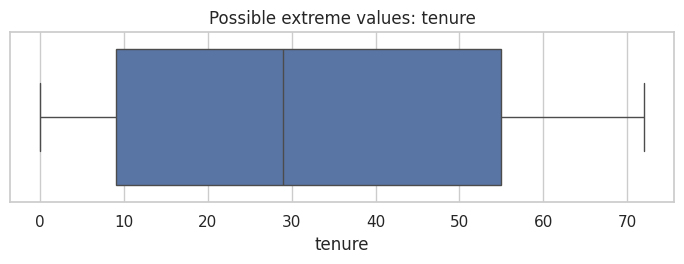

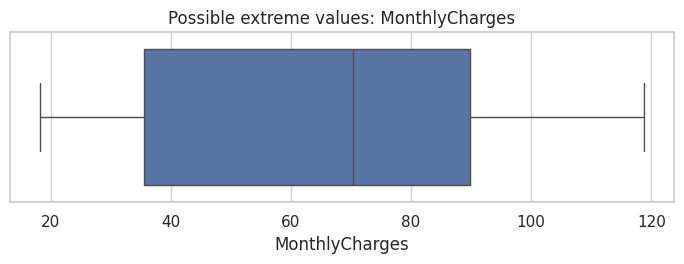

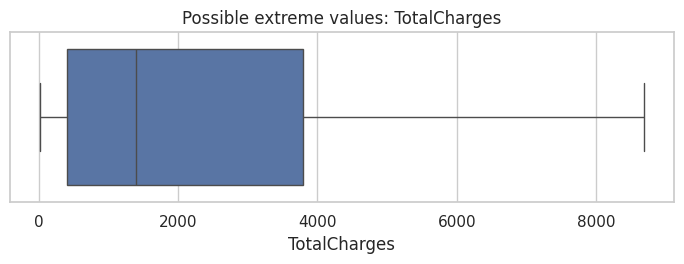

Note: blanks in TotalCharges may occur for customers with tenure = 0.


,tenure,MonthlyCharges,TotalCharges
488,0,52.55,<NA>
753,0,20.25,<NA>
936,0,80.85,<NA>
1082,0,25.75,<NA>
1340,0,56.05,<NA>
3331,0,19.85,<NA>
3826,0,25.35,<NA>
4380,0,20.00,<NA>
5218,0,19.70,<NA>
6670,0,73.35,<NA>


In [ ]:
missing = df.isna().sum().sort_values(ascending=False)
print("Missing values by column:")
display(missing[missing > 0].to_frame("Missing count"))

print("Exact duplicate rows:", df.duplicated().sum())
if "customerID" in df.columns:
    print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

checks = {}
if "tenure" in df.columns:
    checks["tenure outside 0–72 months"] = ((df["tenure"] < 0) | (df["tenure"] > 72)).sum()
if "MonthlyCharges" in df.columns:
    checks["MonthlyCharges <= 0"] = (df["MonthlyCharges"] <= 0).sum()
if "TotalCharges" in df.columns:
    checks["TotalCharges < 0"] = (df["TotalCharges"] < 0).sum()
if "SeniorCitizen" in df.columns:
    checks["SeniorCitizen not 0/1"] = (~df["SeniorCitizen"].isin([0, 1])).sum()
display(pd.Series(checks, name="Count of flagged records").to_frame())

num_for_plot = [c for c in ["tenure", "MonthlyCharges", "TotalCharges"] if c in df.columns]
for col in num_for_plot:
    plt.figure(figsize=(7, 2.8))
    sns.boxplot(x=df[col])
    plt.title(f"Possible extreme values: {col}")
    plt.tight_layout()
    plt.show()

print("Note: blanks in TotalCharges may occur for customers with tenure = 0.")
if {"TotalCharges", "tenure"}.issubset(df.columns):
    display(df.loc[df["TotalCharges"].isna(), ["tenure", "MonthlyCharges", "TotalCharges"]].head(20))


**B3** Target distribution and implications for metrics and splitting

,Count,Percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


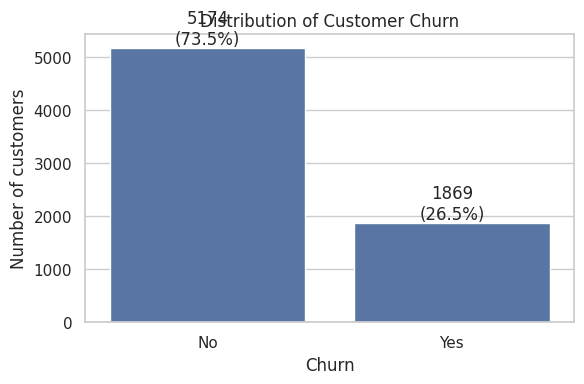

Full target proportions:


,Proportion
Churn,
0,0.73463
1,0.26537


Training target proportions:


,Proportion
Churn,
0,0.734647
1,0.265353


Testing target proportions:


,Proportion
Churn,
0,0.734564
1,0.265436


In [ ]:
target_counts = df[target].value_counts(dropna=False)
target_pct = df[target].value_counts(normalize=True, dropna=False) * 100
target_summary = pd.DataFrame({"Count": target_counts, "Percentage": target_pct.round(2)})
display(target_summary)

plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x=target, order=["No", "Yes"])
ax.set_title("Distribution of Customer Churn")
ax.set_xlabel("Churn")
ax.set_ylabel("Number of customers")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}\n({p.get_height()/len(df)*100:.1f}%)",
                (p.get_x()+p.get_width()/2, p.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.show()

model_df = df.dropna(subset=[target]).copy()
X = model_df.drop(columns=[target, "customerID"], errors="ignore")
y = model_df[target].map({"No": 0, "Yes": 1})
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Full target proportions:")
display(y.value_counts(normalize=True).rename("Proportion"))
print("Training target proportions:")
display(y_train.value_counts(normalize=True).rename("Proportion"))
print("Testing target proportions:")
display(y_test.value_counts(normalize=True).rename("Proportion"))


**B4** Features most related to the target (at least two visualizations)

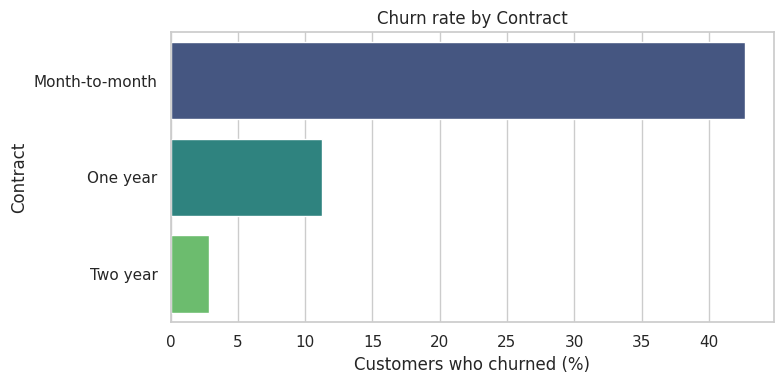

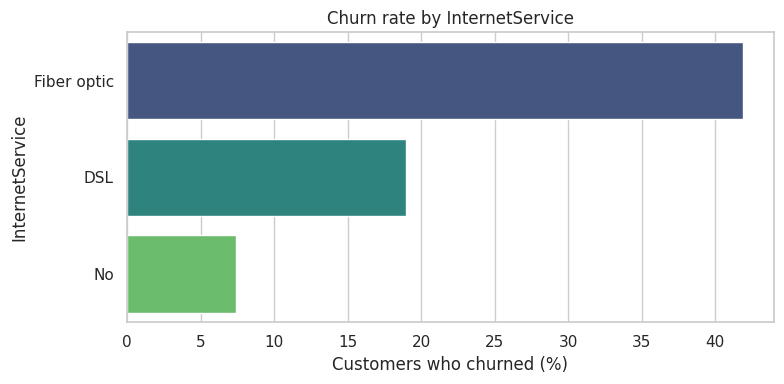

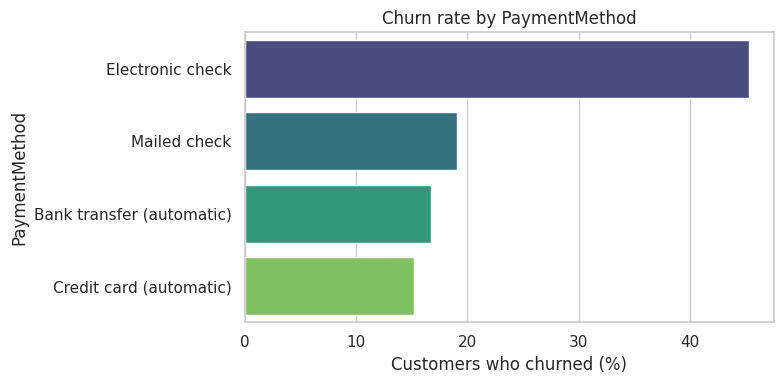

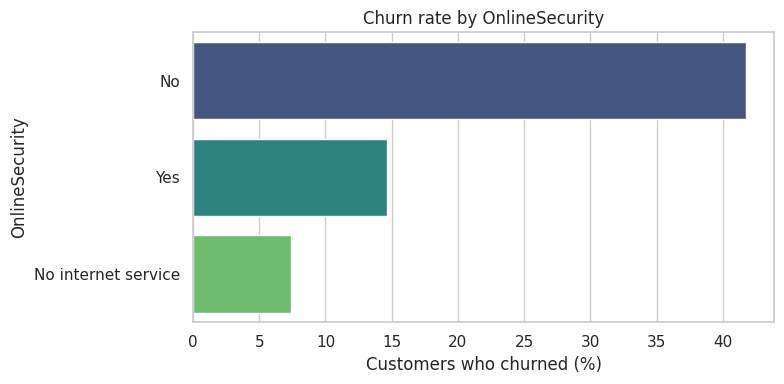

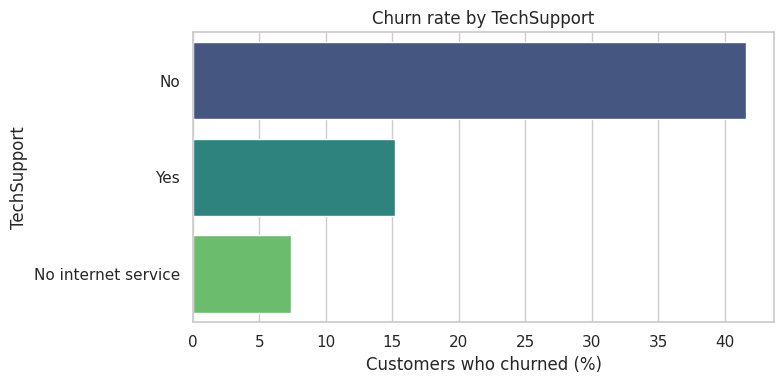

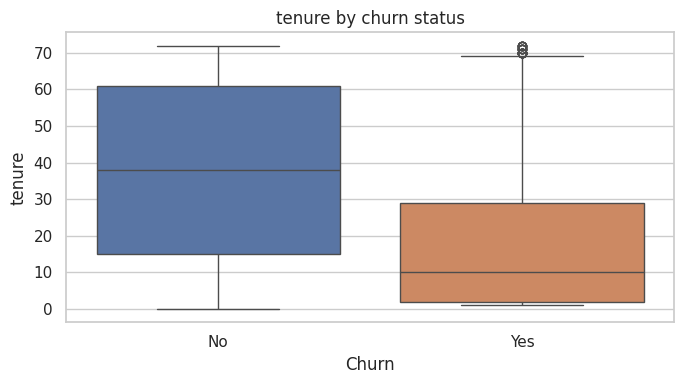

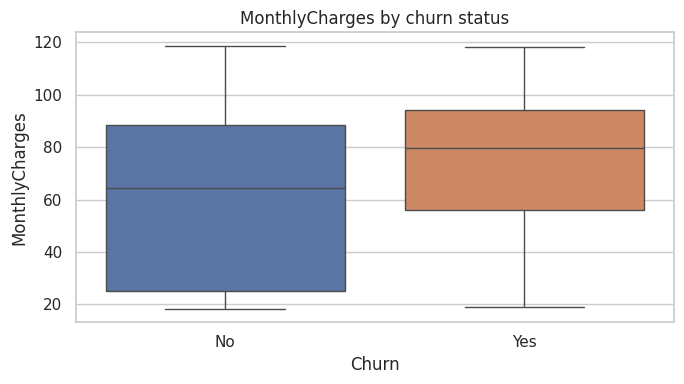

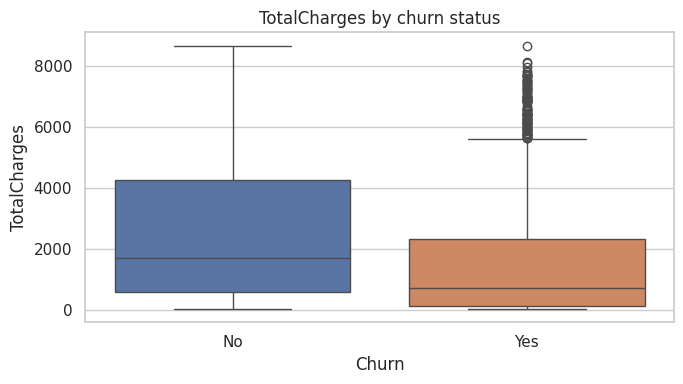

,Feature,Mutual Information
16,Contract,0.098453
1,tenure,0.072536
10,OnlineSecurity,0.064677
13,TechSupport,0.063021
9,InternetService,0.055574
11,OnlineBackup,0.046792
2,MonthlyCharges,0.045770
18,PaymentMethod,0.044519
3,TotalCharges,0.044074
12,DeviceProtection,0.043917


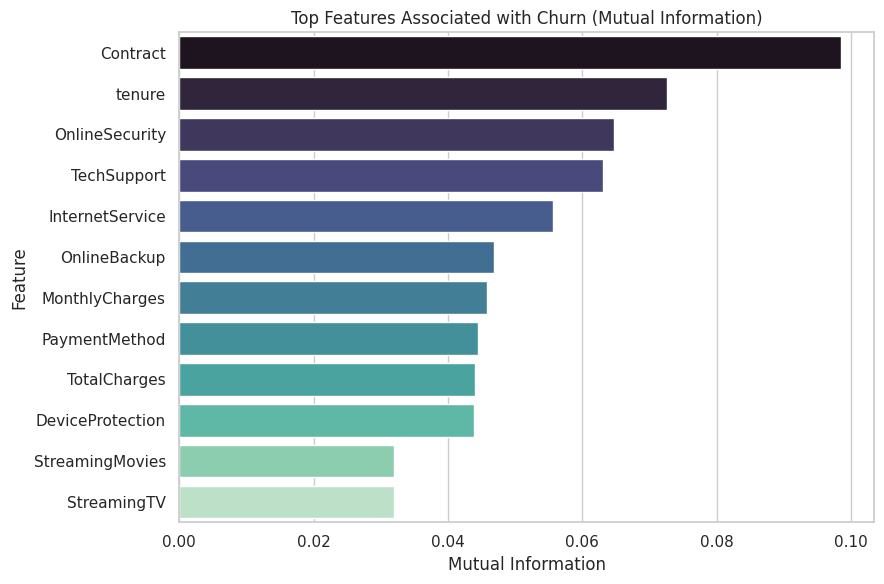

,Feature,Mean decrease in Recall,Std
14,Contract,0.201337,0.006103
4,tenure,0.155882,0.013689
7,InternetService,0.116845,0.014841
18,TotalCharges,0.101337,0.011182
17,MonthlyCharges,0.077540,0.006869
8,OnlineSecurity,0.050267,0.011704
11,TechSupport,0.031283,0.010963
15,PaperlessBilling,0.020321,0.015646
5,PhoneService,0.008289,0.001872
6,MultipleLines,0.008289,0.009063


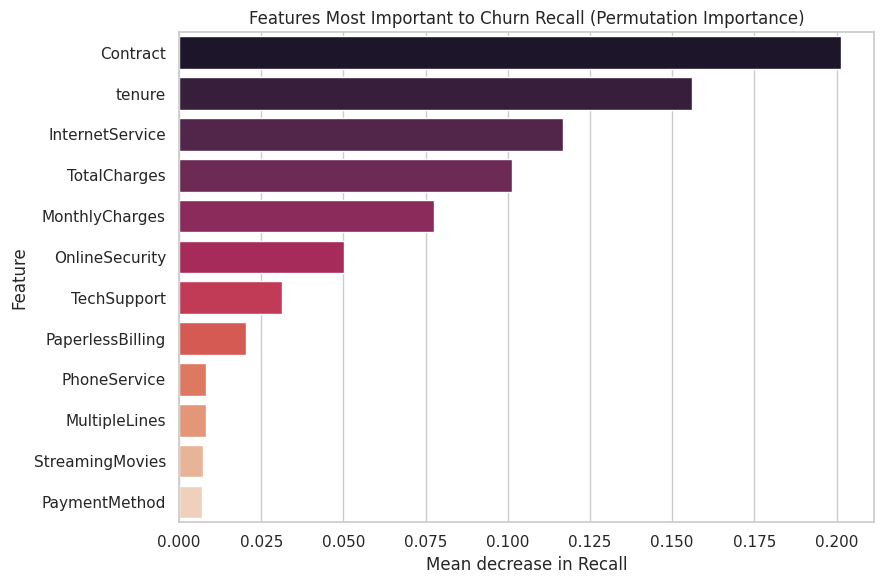

In [ ]:
cat_to_plot = [c for c in ["Contract", "InternetService", "PaymentMethod",
                           "OnlineSecurity", "TechSupport"] if c in df.columns]
for col in cat_to_plot:
    rate = (df.groupby(col, dropna=False)[target]
              .apply(lambda s: (s == "Yes").mean() * 100)
              .sort_values(ascending=False))
    plt.figure(figsize=(8, 4))
    sns.barplot(x=rate.values, y=rate.index, hue=rate.index, legend=False, palette="viridis")
    plt.title(f"Churn rate by {col}")
    plt.xlabel("Customers who churned (%)")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

num_to_plot = [c for c in ["tenure", "MonthlyCharges", "TotalCharges"] if c in df.columns]
for col in num_to_plot:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x=target, y=col, hue=target, legend=False)
    plt.title(f"{col} by churn status")
    plt.tight_layout()
    plt.show()

num_features = X.select_dtypes(include=np.number).columns.tolist()
cat_features = [c for c in X.columns if c not in num_features]
preprocess_mi = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_features)
])
X_mi = preprocess_mi.fit_transform(X)

feature_names = []
discrete_mask = []
for c in num_features:
    feature_names.append(c); discrete_mask.append(False)
for c in cat_features:
    feature_names.append(c); discrete_mask.append(True)

from sklearn.preprocessing import OrdinalEncoder
mi_preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ordinal", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
    ]), cat_features)
])
X_mi_original = mi_preprocessor.fit_transform(X)
mi_discrete = [False] * len(num_features) + [True] * len(cat_features)
mi = mutual_info_classif(X_mi_original, y, discrete_features=mi_discrete, random_state=42)
mi_table = pd.DataFrame({"Feature": num_features + cat_features,
                         "Mutual Information": mi}).sort_values(
                             "Mutual Information", ascending=False)
display(mi_table)

plt.figure(figsize=(9, 6))
sns.barplot(data=mi_table.head(12), x="Mutual Information", y="Feature",
            hue="Feature", legend=False, palette="mako")
plt.title("Top Features Associated with Churn (Mutual Information)")
plt.tight_layout()
plt.show()

numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median"))])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipe, num_features),
    ("categorical", categorical_pipe, cat_features)
])
rf = Pipeline([
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=300, class_weight="balanced",
        random_state=42, n_jobs=-1
    ))
])
rf.fit(X_train, y_train)
perm = permutation_importance(
    rf, X_test, y_test, scoring="recall",
    n_repeats=10, random_state=42, n_jobs=-1
)
perm_table = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean decrease in Recall": perm.importances_mean,
    "Std": perm.importances_std
}).sort_values("Mean decrease in Recall", ascending=False)
display(perm_table)

plt.figure(figsize=(9, 6))
sns.barplot(data=perm_table.head(12), x="Mean decrease in Recall", y="Feature",
            hue="Feature", legend=False, palette="rocket")
plt.title("Features Most Important to Churn Recall (Permutation Importance)")
plt.tight_layout()
plt.show()


**B5** Features strongly related to each other (redundancy / multicollinearity)

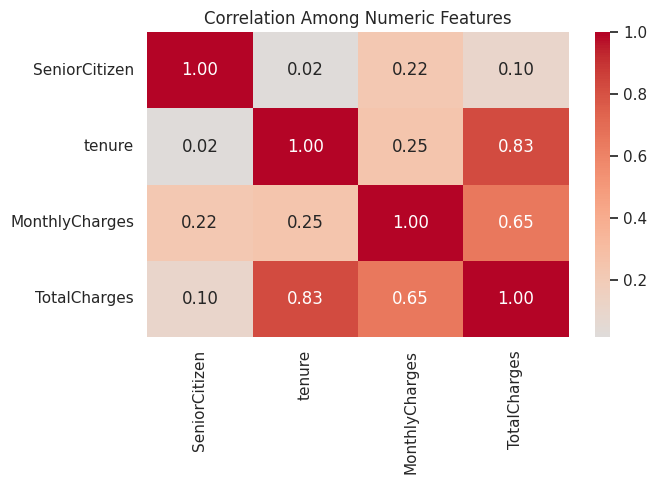

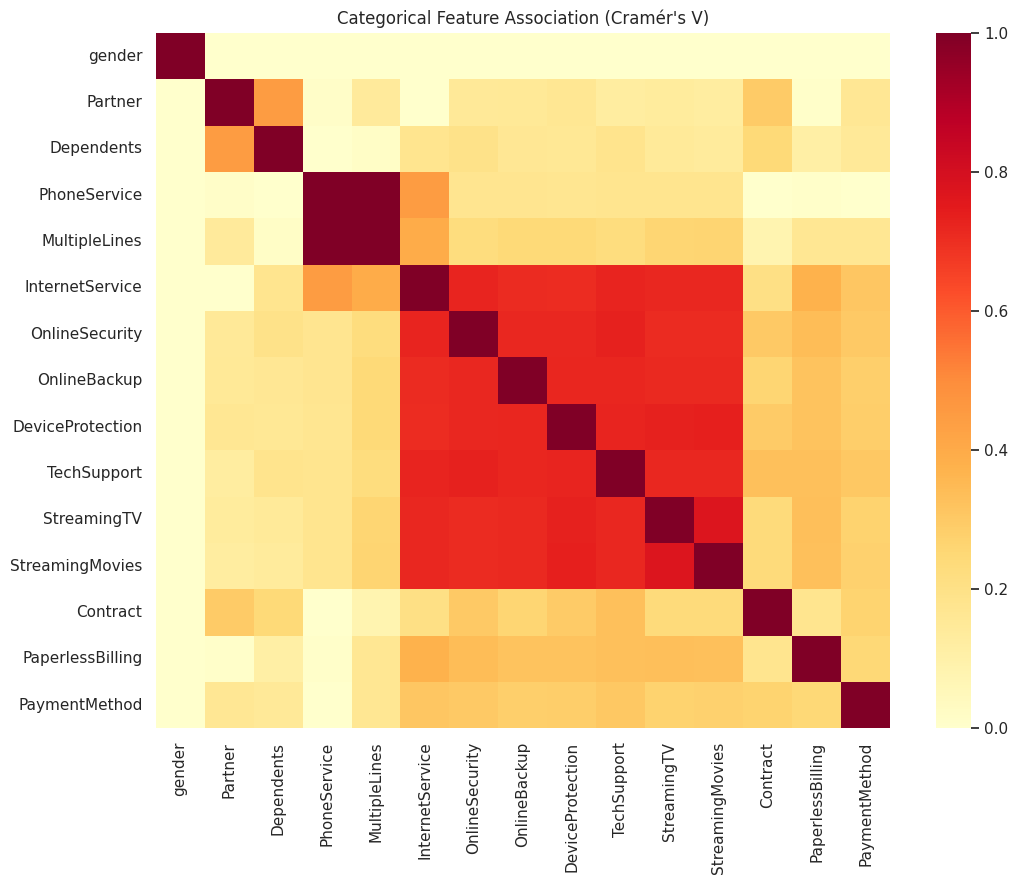

Strongest numeric feature correlations:


Absolute correlation
tenure         TotalCharges                0.825464
MonthlyCharges TotalCharges                0.650864
tenure         MonthlyCharges              0.247900
SeniorCitizen  MonthlyCharges              0.220173
               TotalCharges                0.102652
               tenure                      0.016567

In [ ]:
numeric_predictors = X.select_dtypes(include=np.number).copy()
if not numeric_predictors.empty:
    numeric_predictors = numeric_predictors.fillna(numeric_predictors.median())
    plt.figure(figsize=(7, 5))
    sns.heatmap(numeric_predictors.corr(), annot=True, cmap="coolwarm",
                center=0, fmt=".2f")
    plt.title("Correlation Among Numeric Features")
    plt.tight_layout()
    plt.show()

def cramers_v(a, b):
    table = pd.crosstab(a, b)
    if table.empty or min(table.shape) < 2:
        return np.nan
    chi2 = chi2_contingency(table)[0]
    n = table.to_numpy().sum()
    phi2 = chi2 / n
    r, k = table.shape
    phi2_corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    r_corr = r - ((r-1)**2)/(n-1)
    k_corr = k - ((k-1)**2)/(n-1)
    denom = min(k_corr-1, r_corr-1)
    return np.sqrt(phi2_corr / denom) if denom > 0 else np.nan

cat_predictors = X.select_dtypes(exclude=np.number).columns.tolist()
if len(cat_predictors) >= 2:
    cv = pd.DataFrame(index=cat_predictors, columns=cat_predictors, dtype=float)
    for a in cat_predictors:
        for b in cat_predictors:
            cv.loc[a, b] = 1.0 if a == b else cramers_v(
                X[a].fillna("Missing"), X[b].fillna("Missing"))
    plt.figure(figsize=(11, 9))
    sns.heatmap(cv.astype(float), cmap="YlOrRd", vmin=0, vmax=1)
    plt.title("Categorical Feature Association (Cramér's V)")
    plt.tight_layout()
    plt.show()

if len(numeric_predictors.columns) > 1:
    corr = numeric_predictors.corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    strongest = upper.stack().sort_values(ascending=False)
    print("Strongest numeric feature correlations:")
    display(strongest.head(10).rename("Absolute correlation").to_frame())


**B6** Surprising pattern or hypothesis and how to test it

In [ ]:
if "Contract" in df.columns:
    contract_churn = pd.crosstab(df["Contract"], df[target], normalize="index") * 100
    print("Churn percentage within each contract type:")
    display(contract_churn.round(2))


    contingency = pd.crosstab(df["Contract"], df[target])
    chi2, p_value, dof, expected = chi2_contingency(contingency)
    print(f"Chi-square test: chi2={chi2:.3f}, df={dof}, p-value={p_value:.6g}")
    print("A small p-value (commonly < 0.05) suggests an association, not causation.")


Churn percentage within each contract type:


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


Chi-square test: chi2=1184.597, df=2, p-value=5.86304e-258
A small p-value (commonly < 0.05) suggests an association, not causation.
